# Завдання: Створити агента технічної підтримки, використовуючи LangGraph.

Агент має автоматично обробляти запити користувачів, класифікувати їх, знаходити відповіді в базі знань і генерувати стислі відповіді.

⚠️ Важливе попередження щодо версій: у цьому завданні використовується LangGraph v1.
____________________________

**Основні вимоги**

Агент повинен:

* Класифікувати кожен запит за типом, категорією та терміновістю
* Знаходити релевантну інформацію в базі FAQ (для всіх запитів без винятку)
* Генерувати стислі відповіді (максимум 50 слів)
* Визначати необхідність ескалації до людини-спеціаліста

In [ ]:
# Встановлення необхідних пакети для роботи з LangGraph v1 та OpenRouter
!pip install -q langchain langchain-core langchain-openai langgraph pydantic

langgraph: 1.2.19


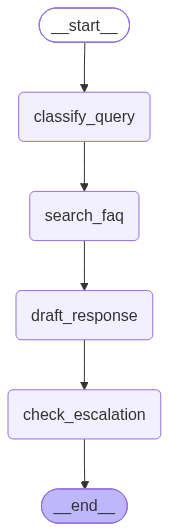

ТЕСТУВАННЯ АГЕНТА ТЕХНІЧНОЇ ПІДТРИМКИ

📧 ТЕСТ 1/5
ЗАПИТ: Я забув пароль від свого акаунту, як його відновити?
----------------------------------------------------------------------

📊 КЛАСИФІКАЦІЯ:
   Тип: problem
   Категорія: password
   Терміновість: medium
   Резюме: Користувач забув пароль від свого акаунту і запитує, як його відновити.

🔍 FAQ (2 пунктів):
   1. Скидання пароля: Натисніть 'Забули пароль?' → введіть email → перевірте пошту
   2. Лист не прийшов - перевірте папку спам

💬 ВІДПОВІДЬ АГЕНТА:
----------------------------------------------------------------------
Натисніть "Забули пароль?", введіть email та перевірте пошту. Якщо листа немає, перевірте папку спам.
----------------------------------------------------------------------

📈 Релевантність: 100%

✅ СТАТУС: Оброблено автоматично

📧 ТЕСТ 2/5
ЗАПИТ: З мене двічі зняли гроші за підписку! Це шахрайство! Поверніть кошти негайно!
----------------------------------------------------------------------

📊 КЛАСИФІКАЦІЯ:
 

In [5]:
import os
import re
from importlib.metadata import version
from typing import List, Literal, Optional, TypedDict

from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langgraph.graph import StateGraph, START, END

print("langgraph:", version("langgraph"))  # очікується 1.x

# ==========================================
# 1. КЛЮЧІ ТА НАЛАШТУВАННЯ МОДЕЛІ
# ==========================================

try:
    from google.colab import userdata
    api_key = userdata.get("OPENROUTER_API_KEY")
except ImportError:  # запуск поза Colab
    api_key = os.getenv("OPENROUTER_API_KEY")

if not api_key:
    raise RuntimeError("Не знайдено OPENROUTER_API_KEY (Colab Secrets або змінна середовища).")

llm = ChatOpenAI(
    model="google/gemini-2.5-flash",
    temperature=0.1,
    api_key=api_key,
    base_url="https://openrouter.ai/api/v1",
)

# ==========================================
# 2. БАЗА ЗНАНЬ ТА ТИПИ ДАНИХ
# ==========================================
FAQ_DATABASE = {
    "password": [
        "Скидання пароля: Натисніть 'Забули пароль?' → введіть email → перевірте пошту",
        "Новий пароль: мінімум 8 символів з літерами та цифрами",
        "Лист не прийшов - перевірте папку спам",
    ],
    "payment": [
        "Перевірте дані картки та баланс",
        "Подвійне списання повернеться автоматично за 3-5 днів",
        "Зміна тарифу: Профіль → Підписка",
    ],
    "technical": [
        "Оновіть сторінку (F5) або очистьте кеш",
        "Спробуйте інший браузер",
        "Перевірте status.ourservice.com",
    ],
    "account": [
        "Перевірте правильність email",
        "Корпоративні акаунти: розділ 'Управління командою'",
        "Блокування - зверніться до підтримки",
    ],
    "general": [
        "Підтримка працює 24/7",
        "Час відповіді: 2-4 години",
    ],
}


class QueryClassification(TypedDict):
    """Структура класифікації"""
    type: Literal["problem", "question", "complaint"]
    category: Literal["password", "payment", "technical", "account", "general"]
    urgency: Literal["low", "medium", "high"]
    summary: str


class SupportAgentState(TypedDict):
    """Стан агента"""
    user_query: str
    classification: Optional[QueryClassification]
    search_results: Optional[List[str]]
    draft_response: Optional[str]
    needs_escalation: bool

# ==========================================
# 3. NODES
# ==========================================

# Вузол 1
CLASSIFY_PROMPT = """Ти — класифікатор запитів служби технічної підтримки.
Визнач для запиту користувача:

type (спершу перевір complaint, потім problem, потім question):
- problem — користувач розповідає, що в нього щось зламалось, не працює або втрачено (забув пароль, не може увійти, виникла помилка) і просить допомогти це виправити. Навіть якщо речення закінчується питанням «як відновити?», це problem, бо проблема вже сталась;
- question — проблеми немає: користувач просто цікавиться, як щось зробити або чи це можливо (змінити тариф, додати користувача);
- complaint — користувач незадоволений: емоційно скаржиться, вимагає, звинувачує, наполягає або нарікає на тривалий збій чи затримку (окличні знаки, «вже кілька годин», «коли нарешті полагодите», «негайно»). Якщо щось не працює І при цьому видно невдоволення чи вимогу, це complaint, а не problem.

category:
- password — вхід в акаунт, забутий, новий або скинутий пароль;
- payment — оплата, списання, повернення коштів, підписка, тарифний план (зокрема його зміна);
- technical — сайт або сервіс не працює, помилки, збої;
- account — акаунт, користувачі та команда, налаштування профілю, блокування;
- general — усе інше.

urgency:
- low — звичайне питання, нічого не горить;
- medium — користувач не може виконати потрібну дію (наприклад, увійти), але серйозних втрат немає;
- high — гроші списано помилково, звинувачення в шахрайстві, довготривала недоступність сервісу, вимога зробити негайно, згадки про суд чи юристів.

summary — одне стисле речення українською в третій особі про суть запиту, починай зі слова «Користувач» (не копіюй запит дослівно).

Запит: {query}"""

VALID_TYPES = ("problem", "question", "complaint")
VALID_CATEGORIES = ("password", "payment", "technical", "account", "general")
VALID_URGENCIES = ("low", "medium", "high")

classifier = llm.with_structured_output(QueryClassification)


def normalize_classification(raw, query: str) -> QueryClassification:
    """Страховка: якщо модель повернула None або значення поза допустимими - підставляємо нейтральні."""
    raw = raw or {}
    return {
        "type": raw.get("type") if raw.get("type") in VALID_TYPES else "question",
        "category": raw.get("category") if raw.get("category") in VALID_CATEGORIES else "general",
        "urgency": raw.get("urgency") if raw.get("urgency") in VALID_URGENCIES else "medium",
        "summary": (raw.get("summary") or query).strip(),
    }


def classify_query(state: SupportAgentState) -> dict:
    raw = classifier.invoke(CLASSIFY_PROMPT.format(query=state["user_query"]))
    return {"classification": normalize_classification(raw, state["user_query"])}


# Вузол 2
SEARCH_PROMPT = """Нижче пронумеровані пункти бази знань (FAQ) і запит користувача.
Обери пункти, які допомагають відповісти на запит, від найрелевантнішого:
- 2 пункти, якщо другий дає корисний додатковий крок або запасний варіант;
- 1 пункт, якщо він повністю відповідає на запит.
Більше двох не обирай, нерелевантні пункти не додавай. Поверни лише номери.

FAQ:
{faq}

Запит: {query}"""


class FAQSelection(BaseModel):
    numbers: List[int] = Field(description="Номери (з 1) найрелевантніших пунктів FAQ, 1-2 числа")


faq_selector = llm.with_structured_output(FAQSelection)


def search_faq(state: SupportAgentState) -> dict:
    category = state["classification"]["category"]
    faq_items = FAQ_DATABASE.get(category, FAQ_DATABASE["general"])
    numbered = "\n".join(f"{i}. {item}" for i, item in enumerate(faq_items, start=1))

    selection = faq_selector.invoke(SEARCH_PROMPT.format(faq=numbered, query=state["user_query"]))

    chosen = []
    for n in (selection.numbers if selection else []):
        if 1 <= n <= len(faq_items) and faq_items[n - 1] not in chosen:
            chosen.append(faq_items[n - 1])

    # якщо модель нічого путнього не повернула, тоді беремо перші пункти категорії
    return {"search_results": chosen[:2] or faq_items[:2]}


# Вузол 3
MAX_DRAFT_WORDS = 31  # + повідомлення про ескалацію (до 19 слів) = не більше 50

DRAFT_PROMPT = """Ти — агент технічної підтримки. Напиши відповідь клієнту українською мовою.

Правила:
1. Не більше 28 слів, одне-два повні речення.
2. Пиши природно, як жива людина, звертайся на «ви». Без привітання, вступів, подяк і вибачень, одразу до справи.
3. Спирайся ЛИШЕ на пункти FAQ. Не додавай термінів, умов, назв розділів чи обіцянок, яких там немає.
4. Відповідай саме на запит клієнта (див. резюме), а не переказуй FAQ. Якщо FAQ не відповідає на частину запиту (наприклад, «коли полагодите»), не вигадуй цього, дай те, що є.
5. Шлях по меню пиши з назвами в лапках і стрілкою, як у FAQ: «Профіль → Підписка». Адресу сайту лишай без змін.
6. Не пиши про передачу спеціалісту: це зробить окремий крок.

Резюме запиту: {summary}

Пункти FAQ:
{faq}

Запит клієнта: {query}"""


def as_text(message) -> str:
    content = message.content
    if isinstance(content, list):
        content = "".join(p.get("text", "") if isinstance(p, dict) else str(p) for p in content)
    return content.strip()


def trim_words(text: str, max_words: int) -> str:
    """Обрізає текст до max_words слів, по можливості по межі речення."""
    if len(text.split()) <= max_words:
        return text
    kept, count = [], 0
    for sentence in re.split(r"(?<=[.!?])\s+", text):
        n = len(sentence.split())
        if count + n > max_words:
            break
        kept.append(sentence)
        count += n
    if kept:
        return " ".join(kept)
    return " ".join(text.split()[:max_words]).rstrip(",;:") + "…"


def draft_response(state: SupportAgentState) -> dict:
    prompt = DRAFT_PROMPT.format(
        summary=state["classification"]["summary"],
        faq="\n".join(f"- {item}" for item in state["search_results"]),
        query=state["user_query"],
    )
    text = " ".join(as_text(llm.invoke(prompt)).replace("**", "").split())
    return {"draft_response": trim_words(text, MAX_DRAFT_WORDS)}


# Вузол 4
ESCALATION_KEYWORDS = ["шахрайств", "судов", "юридичн"]
ESCALATION_NOTE = "⚠️ Запит передано спеціалісту (відповідь за 24 год)."  # запасний варіант

HANDOFF_PROMPT = """Клієнт звернувся до служби підтримки. Резюме запиту: {summary}

Напиши ОДНЕ речення українською (не більше 14 слів): запит передано спеціалісту, який перевірить конкретну тему звернення (наприклад, «подвійне списання за підписку», «збій у роботі сайту»).
Назви цю тему. Без вибачень і привітань. Не обіцяй результату чи термінів (наприклад, повернення коштів). Починай зі слів «Ваш запит»."""

def make_handoff_note(summary: str) -> str:
    """Одне речення про передачу спеціалісту, прив'язане до суті запиту; при збої - стандартна примітка."""
    try:
        sentence = trim_words(" ".join(as_text(llm.invoke(HANDOFF_PROMPT.format(summary=summary))).split()), 14)
        if sentence:
            return f"⚠️ {sentence.rstrip('.')} (відповідь за 24 год)."
    except Exception:
        pass
    return ESCALATION_NOTE


def check_escalation(state: SupportAgentState) -> dict:
    cls = state["classification"]
    query = state["user_query"].lower()

    has_keyword = any(kw in query for kw in ESCALATION_KEYWORDS)
    needs_escalation = bool(
        cls["urgency"] == "high" or cls["type"] == "complaint" or has_keyword
    )

    draft = state["draft_response"]
    if needs_escalation:
        draft = f"{draft}\n{make_handoff_note(cls.get('summary') or state['user_query'])}"

    return {"needs_escalation": needs_escalation, "draft_response": draft}

# ==========================================
# 4. ЗБІРКА ГРАФА
# ==========================================

def build_support_agent():
    """Строго послідовний граф: усі чотири вузли для кожного запиту, без умовних ребер."""
    builder = StateGraph(SupportAgentState)

    builder.add_node("classify_query", classify_query)
    builder.add_node("search_faq", search_faq)
    builder.add_node("draft_response", draft_response)
    builder.add_node("check_escalation", check_escalation)

    builder.add_edge(START, "classify_query")
    builder.add_edge("classify_query", "search_faq")
    builder.add_edge("search_faq", "draft_response")
    builder.add_edge("draft_response", "check_escalation")
    builder.add_edge("check_escalation", END)

    return builder.compile()


agent = build_support_agent()

try:
    from IPython.display import Image, display
    display(Image(agent.get_graph().draw_mermaid_png()))
except Exception:  # без мережі до mermaid.ink друкуємо текстову схему
    print(agent.get_graph().draw_mermaid())

# ==========================================
# 5. ТЕСТУВАННЯ ТА ОБЧИСЛЕННЯ МЕТРИК
# ==========================================

def calculate_answer_relevancy(query: str, response: str) -> float:
    """Оцінка релевантності"""

    relevancy_prompt = f"""
    Оцінка релевантності (0-1):
    Запит: {query}
    Відповідь: {response}

    Тільки число:
    """

    try:
        result = llm.invoke(relevancy_prompt)
        text = as_text(result)
        score = float(re.search(r"\d+(?:[.,]\d+)?", text).group().replace(",", "."))
        if 1 < score <= 100:  # модель відповіла у відсотках
            score /= 100
        return min(max(score, 0.0), 1.0)
    except Exception:
        return 0.5


def test_agent():
    """Тестування агента на 5 запитах"""

    agent = build_support_agent()

    test_queries = [
        "Я забув пароль від свого акаунту, як його відновити?",
        "З мене двічі зняли гроші за підписку! Це шахрайство! Поверніть кошти негайно!",
        "Чи можу я змінити тарифний план на дешевший?",
        "Сайт не працює вже третю годину! Коли полагодите?",
        "Як додати нового користувача до корпоративного акаунту?",
    ]

    results = []
    relevancy_scores = []

    print("=" * 70)
    print("ТЕСТУВАННЯ АГЕНТА ТЕХНІЧНОЇ ПІДТРИМКИ")
    print("=" * 70)

    for i, query in enumerate(test_queries, 1):
        print(f"\n{'='*70}")
        print(f"📧 ТЕСТ {i}/5")
        print(f"{'='*70}")
        print(f"ЗАПИТ: {query}")
        print("-" * 70)

        initial_state = {
            "user_query": query,
            "needs_escalation": False
        }

        config = {"configurable": {"thread_id": f"test_{i}"}}

        try:
            result = agent.invoke(initial_state, config)
            results.append(result)

            # Виводимо класифікацію
            if result.get("classification"):
                cls = result["classification"]
                print(f"\n📊 КЛАСИФІКАЦІЯ:")
                print(f"   Тип: {cls.get('type')}")
                print(f"   Категорія: {cls.get('category')}")
                print(f"   Терміновість: {cls.get('urgency')}")
                print(f"   Резюме: {cls.get('summary')}")

            # Виводимо знайдені FAQ
            if result.get("search_results"):
                print(f"\n🔍 FAQ ({len(result['search_results'])} пунктів):")
                for j, faq in enumerate(result['search_results'], 1):
                    print(f"   {j}. {faq}")

            # ВИВОДИМО ВІДПОВІДЬ АГЕНТА
            if result.get("draft_response"):
                print(f"\n💬 ВІДПОВІДЬ АГЕНТА:")
                print("-" * 70)
                print(result["draft_response"])
                print("-" * 70)

                # Рахуємо релевантність
                relevancy = calculate_answer_relevancy(query, result["draft_response"])
                relevancy_scores.append(relevancy)
                print(f"\n📈 Релевантність: {relevancy:.0%}")

            # Статус ескалації
            if result.get("needs_escalation"):
                print("\n⚠️ СТАТУС: Ескаловано до спеціаліста")
            else:
                print("\n✅ СТАТУС: Оброблено автоматично")

        except Exception as e:
            print(f"❌ ПОМИЛКА: {e}")
            results.append({})

    # Фінальні метрики
    print(f"\n{'='*70}")
    print("ПІДСУМКОВІ МЕТРИКИ")
    print("=" * 70)

    # Task Completion Rate
    completed = sum(1 for r in results if r.get("draft_response"))
    tcr = completed / len(results) if results else 0
    print(f"✅ Task Completion Rate: {tcr:.0%} ({completed}/{len(results)})")

    # Answer Relevancy
    if relevancy_scores:
        avg_relevancy = sum(relevancy_scores) / len(relevancy_scores)
        print(f"🎯 Average Answer Relevancy: {avg_relevancy:.0%}")

    # Escalation Rate
    escalated = sum(1 for r in results if r.get("needs_escalation"))
    print(f"📊 Escalation Rate: {escalated}/{len(results)} ({escalated/len(results)*100:.0f}%)")

    print("=" * 70)

    return results

results = test_agent()

# ==========================================
# 6. ПЕРЕВІРКА
# ==========================================

EXPECTED = [
    {"type": "problem",   "category": "password",  "urgency": "medium", "escalation": False},
    {"type": "complaint", "category": "payment",   "urgency": "high",   "escalation": True},
    {"type": "question",  "category": "payment",   "urgency": "low",    "escalation": False},
    {"type": "complaint", "category": "technical", "urgency": "high",   "escalation": True},
    {"type": "question",  "category": "account",   "urgency": "low",    "escalation": False},
]

def check_requirements(results):
    ok = lambda flag: "✅" if flag else "❌"
    all_passed = True

    for i, (res, exp) in enumerate(zip(results, EXPECTED), 1):
        cls = res.get("classification") or {}
        faq = res.get("search_results") or []
        answer = res.get("draft_response") or ""
        words = len(answer.split())
        text_only = re.sub(r"[A-Za-z0-9_.:/()-]*[A-Za-z][A-Za-z0-9_.:/()-]*", " ", answer)  # без URL та F5
        letters = [c for c in text_only if c.isalpha()]
        cyrillic_share = sum("а" <= c.lower() <= "я" or c.lower() in "іїєґ" for c in letters) / max(len(letters), 1)

        checks = {
            f"тип = {exp['type']} (є {cls.get('type')})": cls.get("type") == exp["type"],
            f"категорія = {exp['category']} (є {cls.get('category')})": cls.get("category") == exp["category"],
            f"терміновість = {exp['urgency']} (є {cls.get('urgency')})": cls.get("urgency") == exp["urgency"],
            f"ескалація = {exp['escalation']} (є {res.get('needs_escalation')})": res.get("needs_escalation") == exp["escalation"],
            f"FAQ: 1-2 пункти з категорії ({len(faq)})": 1 <= len(faq) <= 2 and all(f in FAQ_DATABASE.get(exp["category"], []) for f in faq),
            f"відповідь ≤ 50 слів ({words})": 0 < words <= 50,
            "відповідь українською": cyrillic_share > 0.8,
        }
        print(f"Запит {i}:")
        for name, flag in checks.items():
            print(f"   {ok(flag)} {name}")
            all_passed &= flag

    print("\n" + ("✅ Усі перевірки пройдено" if all_passed else "❌ Є невідповідності - див. ❌ вище"))


check_requirements(results)
